# 05 · Pitch: Welche Apertus-Variante findet die Suva-Fälle?

Fünf Varianten der Relevanz-Bewertung (Abis Pipeline #62, `triage.cli relevance`), die im Endprodukt per Option wählbar sein sollen:

| Variante | Modell | Durchgänge |
|---|---|---|
| 8B · 1 Durchgang | `apertus-v1-5-8b` | nur Bewertung mit Belegen |
| 8B · 2 Durchgänge | `apertus-v1-5-8b` | Bewertung + Vertiefung (ab Score 50) |
| 70B · 1 Durchgang | `apertus-v1-5-70b` | nur Bewertung mit Belegen |
| 70B · 2 Durchgänge | `apertus-v1-5-70b` | Bewertung + Vertiefung (eingestellt) |
| 70B Thinking · 2 Durchgänge | `apertus-v1-5-70b-thinking` | Bewertung + Vertiefung im Reasoning-Modus |

Dazu als Vergleich **heute**: Ähnlichkeit zur Vector-DB ohne Apertus.

**Messung** wie `results/relevance_eval.md`: Q4/2025 und Q1/2026, zusammen **59 Suva-Fälle**. Jedes Quartal wird nur mit Wissen aus dem anderen bewertet (Hold-out).
„1 Durchgang“ nutzt dieselben Antworten ohne den zweiten Aufruf: Der zweite Durchgang ist ein eigener Aufruf, der nur bei Score ≥ 50 läuft.

Die Grafiken werden als PNG (1920 × 1080) in `results/figures/` gespeichert, direkt für die Folien.


In [1]:
import os
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from hack_apertus_coffee_exe.eval.compare import (
    FOLDS, abi_two_pass, apertus_calls, calibrated_lists, combine_ranks, fold_metrics, recall_curve_pooled, stage1,
)
from hack_apertus_coffee_exe.eval.relevance import Corpus, open_vectordb

FIG_DIR = Path("results/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Folien-Stil: grosse Schrift, ruhige Achsen, weisser Grund
plt.rcParams.update({
    "figure.figsize": (12, 6.75), "figure.dpi": 160, "savefig.dpi": 160, "figure.facecolor": "white",
    "font.size": 14, "axes.titlesize": 19, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 14, "axes.labelcolor": "#444444", "xtick.color": "#666666", "ytick.color": "#666666",
    "axes.edgecolor": "#cccccc", "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "legend.fontsize": 13,
})
INK, MUTED, GRID = "#191919", "#666666", "#e6e6e6"

# Feste Farbe pro Modell; 1 Durchgang = hell/gestrichelt, 2 Durchgänge = kräftig/durchgezogen
VARIANTS = {
    "Heute: Ähnlichkeit, ohne Apertus": dict(dir=None, passes=0, color="#9c9c9c", light=False, model="–"),
    "8B · 1 Durchgang": dict(dir="results/tables/twopass_8b", passes=1, color="#257de0", light=True, model="apertus-v1-5-8b"),
    "8B · 2 Durchgänge": dict(dir="results/tables/twopass_8b", passes=2, color="#257de0", light=False, model="apertus-v1-5-8b"),
    "70B · 1 Durchgang": dict(dir="results/tables", passes=1, color="#f47230", light=True, model="apertus-v1-5-70b"),
    "70B · 2 Durchgänge": dict(dir="results/tables", passes=2, color="#f47230", light=False, model="apertus-v1-5-70b"),
    "70B Thinking · 2 Durchgänge": dict(dir="results/tables/thinking_70b", passes=2, color="#6a4ce2", light=False,
                                        model="apertus-v1-5-70b-thinking"),
}

def tint(hex_color, amount=0.55):
    rgb = np.array([int(hex_color[i:i + 2], 16) for i in (1, 3, 5)]) / 255
    return tuple(rgb + (1 - rgb) * amount)

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", facecolor="white")
    print("gespeichert:", FIG_DIR / f"{name}.png")

corpus = Corpus(open_vectordb())

## Kennzahlen aller Varianten

In [2]:
base = {f.name: stage1(corpus, f, "similarity", False) for f in FOLDS}   # heutige Rangliste
rankings, rows = {}, []
for name, v in VARIANTS.items():
    frames = [combine_ranks(base[f.name], abi_two_pass(corpus, f, v["dir"], v["passes"]) if v["dir"] else None, 1.0)
              for f in FOLDS]
    rankings[name] = frames
    m = [fold_metrics(fr) for fr in frames]
    row = {"Variante": name, "Modell": v["model"],
           "Top 30 je Quartal (von 59)": sum(x["top30"] for x in m),
           "Gefunden in den ersten 100 je Quartal": sum(x["top100"] for x in m),
           "Liste für alle 59": sum(x["len100"] for x in m),
           "Apertus-Aufrufe (2 Quartale)": sum(apertus_calls(v["dir"], f.name, v["passes"]) for f in FOLDS) if v["dir"] else 0}
    if v["dir"]:
        cal = calibrated_lists(v["dir"], v["passes"]).set_index("list_factor")
        row.update({"F2-Liste: gefunden": int(cal.loc[1.0, "Gefunden (von 59)"]), "F2-Liste: Länge": int(cal.loc[1.0, "Auf der Liste"]),
                    "F2": cal.loc[1.0, "F2"], "Liste 0.3: Länge": int(cal.loc[0.3, "Auf der Liste"]),
                    "Liste 0.3: gefunden": int(cal.loc[0.3, "Gefunden (von 59)"])})
    rows.append(row)
summary = pd.DataFrame(rows).set_index("Variante").convert_dtypes()
summary.to_csv("results/tables/pitch_varianten.csv")
summary

,Modell,Top 30 je Quartal (von 59),Gefunden in den ersten 100 je Quartal,Liste für alle 59,Apertus-Aufrufe (2 Quartale),F2-Liste: gefunden,F2-Liste: Länge,F2,Liste 0.3: Länge,Liste 0.3: gefunden
Variante,,,,,,,,,,
"Heute: Ähnlichkeit, ohne Apertus",–,32,51,2039,0,<NA>,<NA>,<NA>,<NA>,<NA>
8B · 1 Durchgang,apertus-v1-5-8b,36,55,238,300,48,127,0.661157,255,59
8B · 2 Durchgänge,apertus-v1-5-8b,35,55,240,547,47,108,0.68314,225,57
70B · 1 Durchgang,apertus-v1-5-70b,36,58,208,300,43,70,0.702614,235,59
70B · 2 Durchgänge,apertus-v1-5-70b,38,57,195,521,49,97,0.735736,226,59
70B Thinking · 2 Durchgänge,apertus-v1-5-70b-thinking,37,59,186,519,50,101,0.74184,226,59


**Spalten:** *Top 30*: Suva-Fälle unter den ersten 30 jedes Quartals (Erfolgskriterium der Challenge). *Liste für alle 59*: so viele Urteile müsste Suva lesen, um alle Suva-Fälle zu finden.
*F2-Liste*: Liste mit der kalibrierten Schwelle (bestes F2, `list_factor` 1.0). *Liste 0.3*: eingestellte, längere Liste für höchsten Recall (`configs/triage.json`).


## Folie 1: Wie schnell finden wir die Suva-Fälle?

gespeichert: results/figures/pitch_1_recall_kurven.png


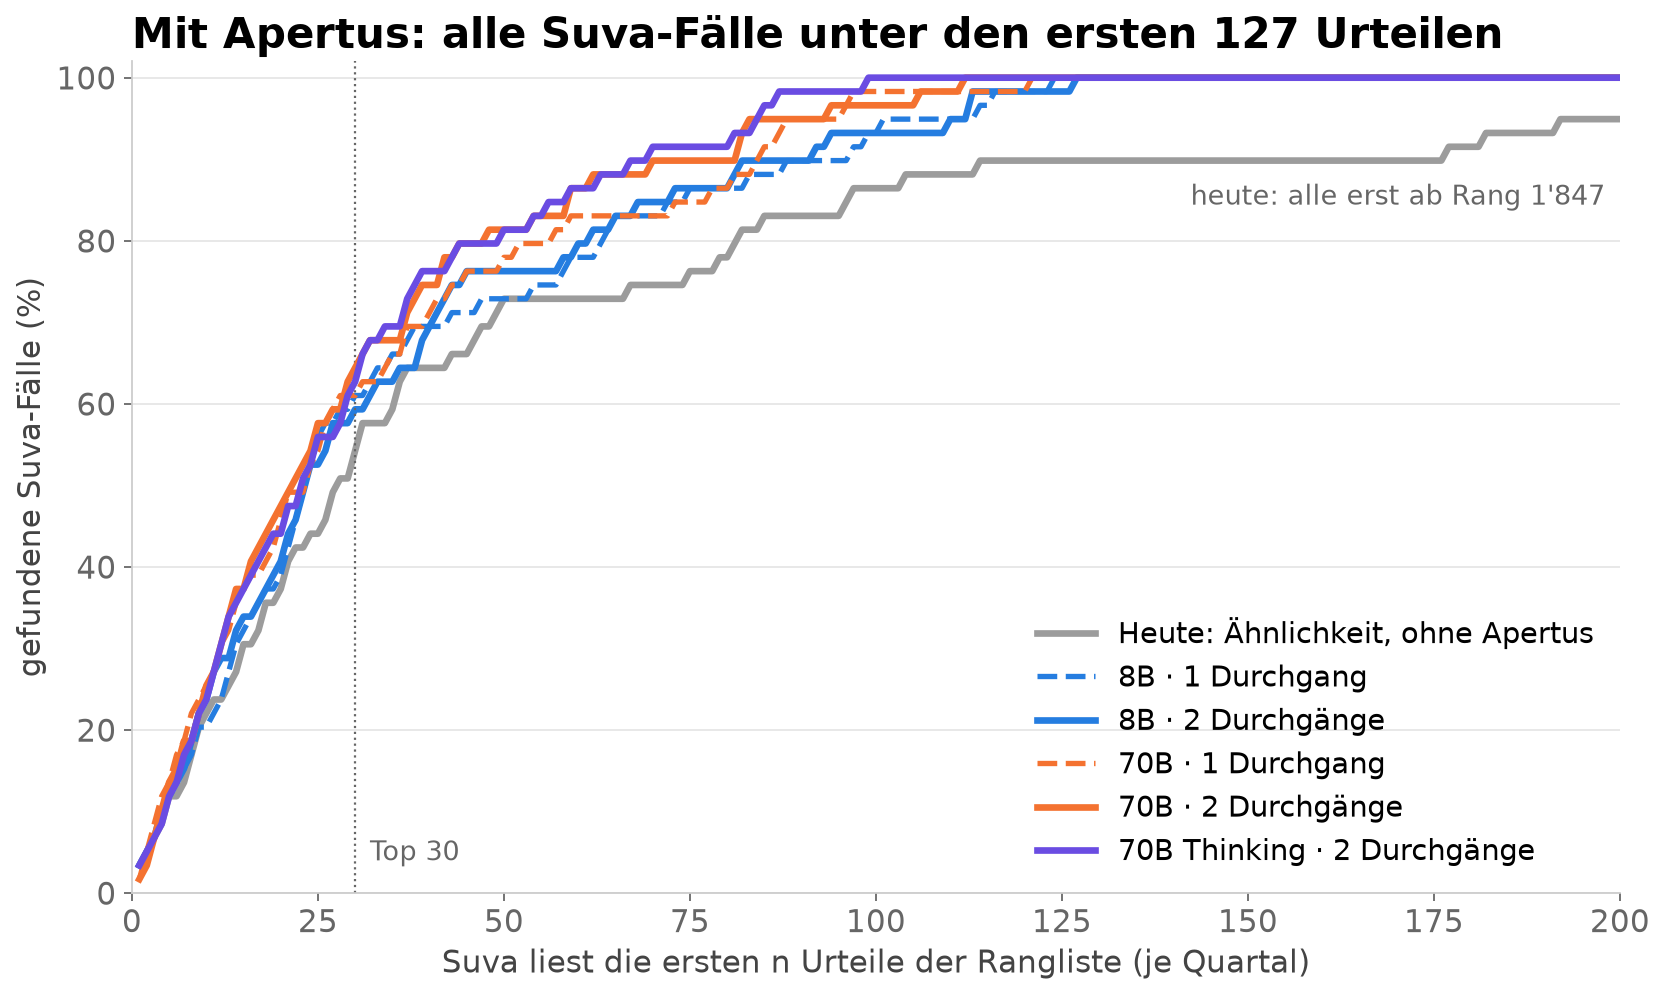

In [3]:
fig, ax = plt.subplots()
for name, v in VARIANTS.items():
    curve = recall_curve_pooled(rankings[name], 200) * 100
    ax.plot(curve.index, curve.values, color=v["color"], linewidth=3 if not v["light"] else 2.4,
            linestyle="--" if v["light"] else "-", label=name, zorder=3 if name.startswith("70B") else 2)
ax.axvline(30, color=MUTED, linewidth=1, linestyle=":")
ax.text(32, 4, "Top 30", color=MUTED, fontsize=12)
ax.set_xlim(0, 200)
ax.set_ylim(0, 102)
ax.set_xlabel("Suva liest die ersten n Urteile der Rangliste (je Quartal)")
ax.set_ylabel("gefundene Suva-Fälle (%)")
ax.yaxis.grid(True, color=GRID)
ax.set_axisbelow(True)
full = {n: int((recall_curve_pooled(rankings[n], 2500) >= 1).idxmax()) for n in VARIANTS}
ax.set_title(f"Mit Apertus: alle Suva-Fälle unter den ersten {max(v for k, v in full.items() if VARIANTS[k]['dir'])} Urteilen")
ax.text(198, 87, f"heute: alle erst ab Rang {full['Heute: Ähnlichkeit, ohne Apertus']:,}".replace(",", "'"),
        ha="right", va="top", color=MUTED, fontsize=12)
ax.legend(loc="lower right")
save(fig, "pitch_1_recall_kurven")
plt.show()

## Folie 2: Wie viel muss Suva lesen, um alle 59 Fälle zu finden?

gespeichert: results/figures/pitch_2_lesemenge_alle_faelle.png


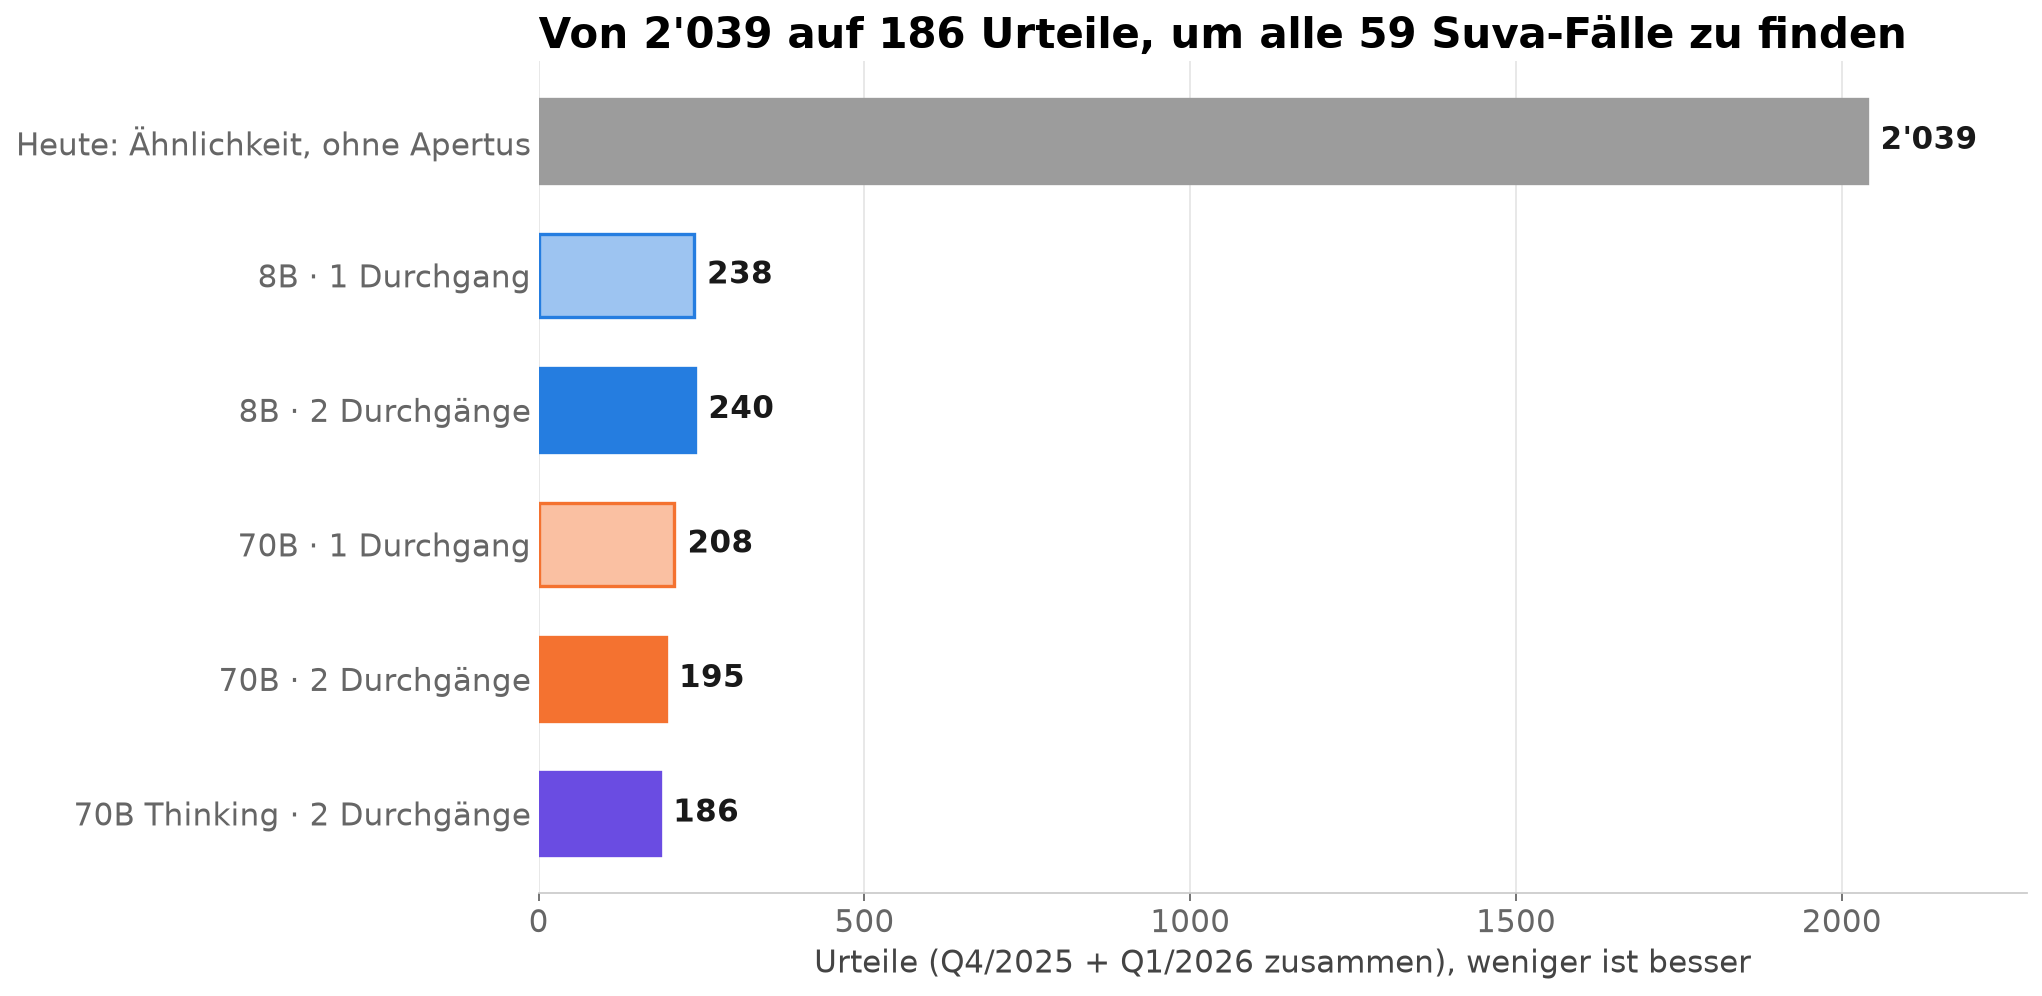

In [4]:
order = list(VARIANTS)[::-1]
values = summary.loc[order, "Liste für alle 59"]
fig, ax = plt.subplots()
for i, name in enumerate(order):
    v = VARIANTS[name]
    ax.barh(i, values[name], height=0.62, color=tint(v["color"]) if v["light"] else v["color"],
            edgecolor=v["color"], linewidth=1.5)
    ax.text(values[name] + values.max() * 0.01, i, f"{values[name]:,}".replace(",", "'"), va="center", fontsize=14,
            color=INK, fontweight="bold")
ax.set_yticks(range(len(order)), order)
ax.set_xlim(0, values.max() * 1.12)
ax.set_xlabel("Urteile (Q4/2025 + Q1/2026 zusammen), weniger ist besser")
ax.xaxis.grid(True, color=GRID)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
best = values.drop("Heute: Ähnlichkeit, ohne Apertus").min()
today = f"{values['Heute: Ähnlichkeit, ohne Apertus']:,}".replace(",", "'")
ax.set_title(f"Von {today} auf {best} Urteile, um alle 59 Suva-Fälle zu finden")
save(fig, "pitch_2_lesemenge_alle_faelle")
plt.show()

## Folie 3: Wie treffsicher ist die Liste?

gespeichert: results/figures/pitch_3_treffsicherheit_liste.png


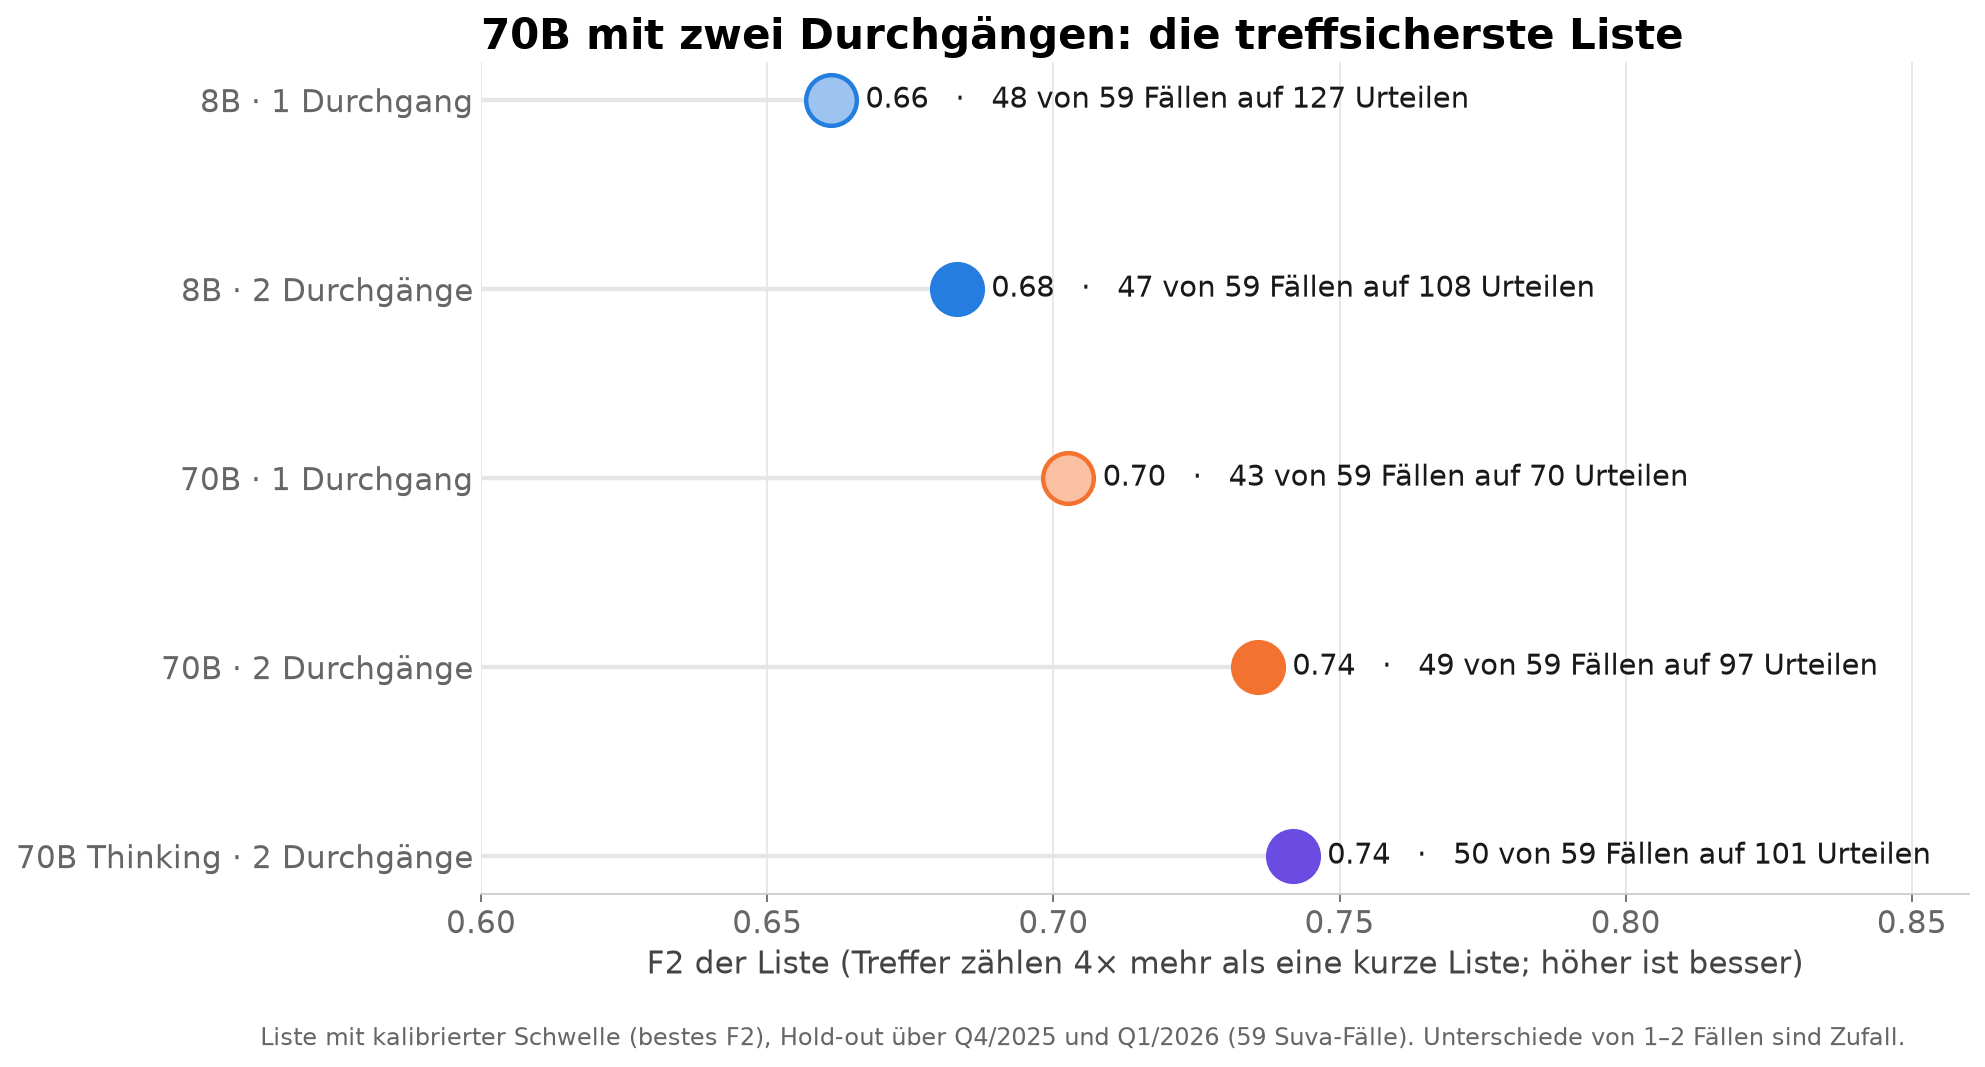

In [5]:
apertus = [n for n in VARIANTS if VARIANTS[n]["dir"]]
f2 = summary.loc[apertus, "F2"]
fig, ax = plt.subplots()
for i, name in enumerate(apertus[::-1]):
    v = VARIANTS[name]
    ax.hlines(i, 0.6, f2[name], color=GRID, linewidth=2, zorder=1)
    ax.scatter(f2[name], i, s=520, color=tint(v["color"]) if v["light"] else v["color"], edgecolor=v["color"],
               linewidth=2, zorder=3)
    found, length = int(summary.loc[name, "F2-Liste: gefunden"]), int(summary.loc[name, "F2-Liste: Länge"])
    ax.text(f2[name] + 0.006, i, f"{f2[name]:.2f}   ·   {found} von 59 Fällen auf {length} Urteilen",
            va="center", fontsize=13, color=INK)
ax.set_yticks(range(len(apertus)), apertus[::-1])
ax.set_xlim(0.6, 0.86)
ax.set_xlabel("F2 der Liste (Treffer zählen 4× mehr als eine kurze Liste; höher ist besser)")
ax.xaxis.grid(True, color=GRID)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_title("70B mit zwei Durchgängen: die treffsicherste Liste")
fig.text(0.01, -0.03, "Liste mit kalibrierter Schwelle (bestes F2), Hold-out über Q4/2025 und Q1/2026 (59 Suva-Fälle). "
         "Unterschiede von 1–2 Fällen sind Zufall.", fontsize=11, color=MUTED)
save(fig, "pitch_3_treffsicherheit_liste")
plt.show()

## Folie 4: Aufwand gegen Nutzen

gespeichert: results/figures/pitch_4_aufwand_nutzen.png


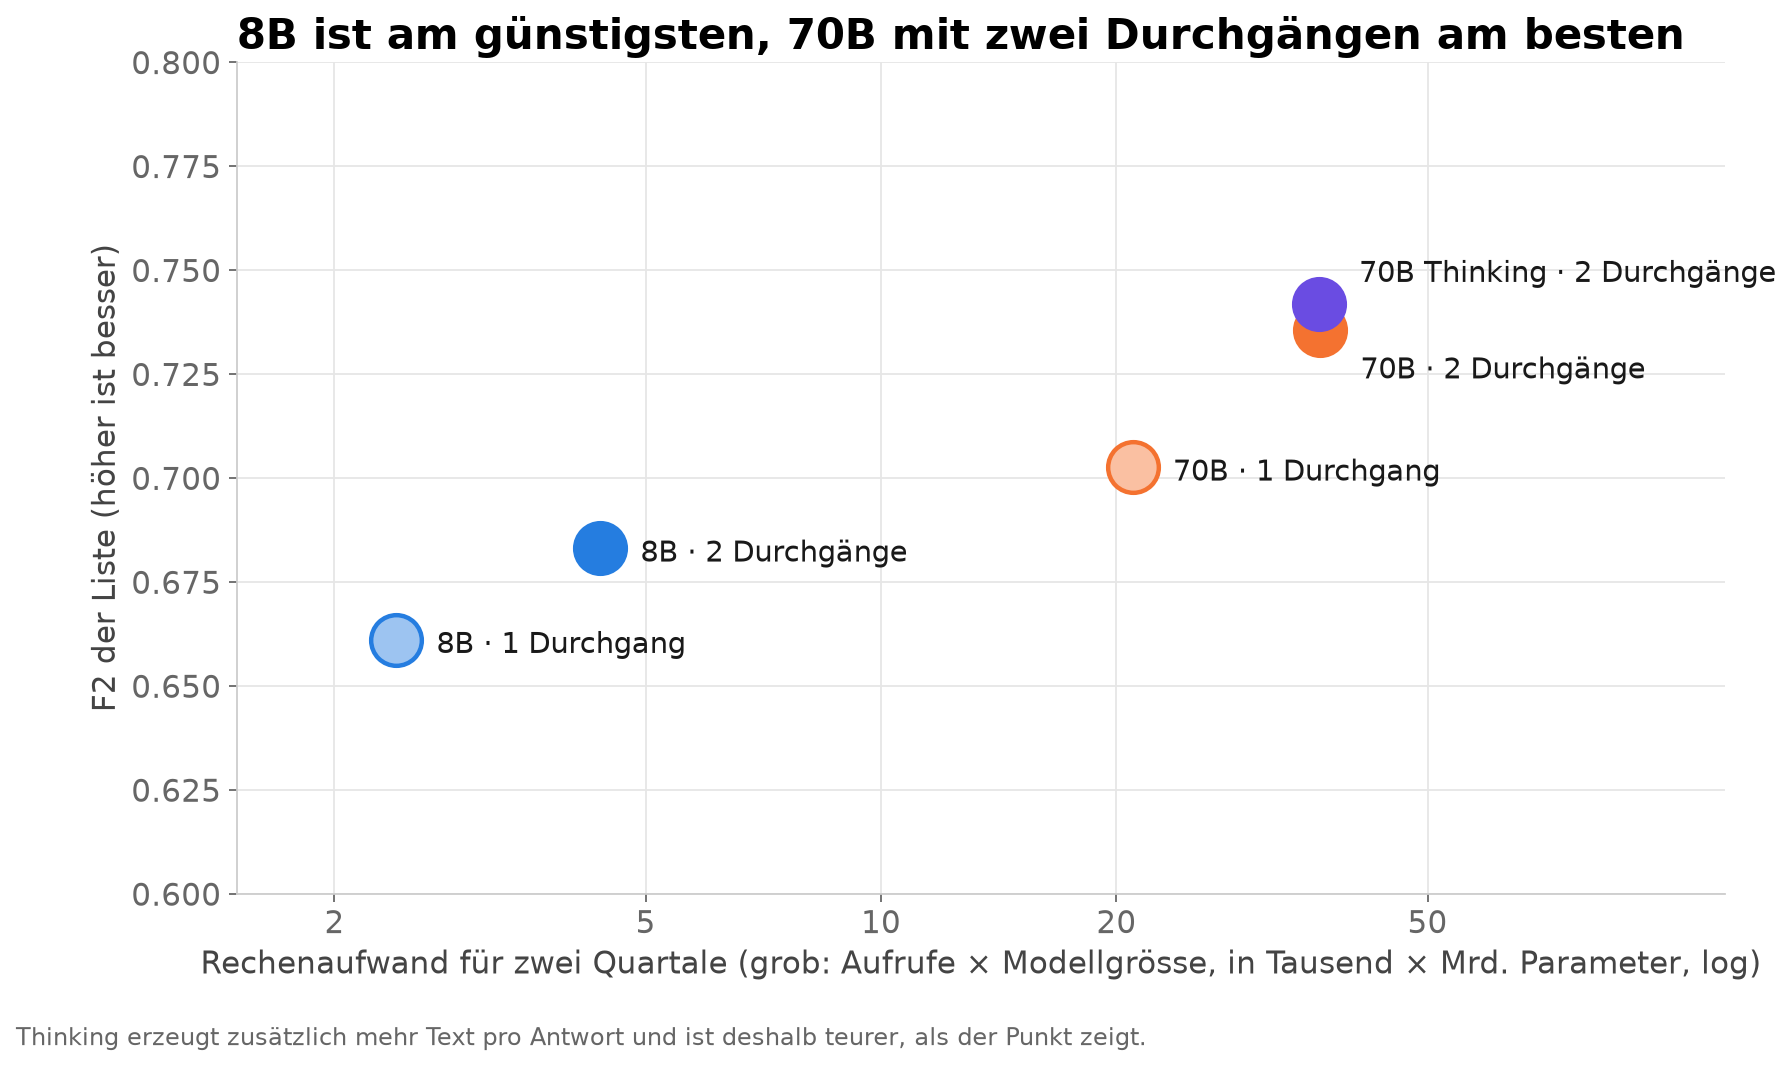

In [6]:
SIZE = {"apertus-v1-5-8b": 8, "apertus-v1-5-70b": 70, "apertus-v1-5-70b-thinking": 70}   # Mrd. Parameter
fig, ax = plt.subplots()
for name in apertus:
    v = VARIANTS[name]
    effort = summary.loc[name, "Apertus-Aufrufe (2 Quartale)"] * SIZE[v["model"]] / 1000
    ax.scatter(effort, f2[name], s=520, color=tint(v["color"]) if v["light"] else v["color"], edgecolor=v["color"],
               linewidth=2, zorder=3)
    dy = {"70B Thinking · 2 Durchgänge": 10, "70B · 2 Durchgänge": -22}.get(name, -6)
    ax.annotate(name, (effort, f2[name]), xytext=(18, dy), textcoords="offset points", fontsize=13, color=INK)
ax.set_xscale("log")
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.set_xticks([2, 5, 10, 20, 50], ["2", "5", "10", "20", "50"])
ax.set_xlim(1.5, 120)
ax.set_ylim(0.6, 0.8)
ax.set_xlabel("Rechenaufwand für zwei Quartale (grob: Aufrufe × Modellgrösse, in Tausend × Mrd. Parameter, log)")
ax.set_ylabel("F2 der Liste (höher ist besser)")
ax.grid(True, color=GRID)
ax.set_axisbelow(True)
ax.set_title("8B ist am günstigsten, 70B mit zwei Durchgängen am besten")
fig.text(0.01, -0.03, "Thinking erzeugt zusätzlich mehr Text pro Antwort und ist deshalb teurer, als der Punkt zeigt.",
         fontsize=11, color=MUTED)
save(fig, "pitch_4_aufwand_nutzen")
plt.show()

## Fazit für den Pitch

| Variante | Top 30 (von 59) | Liste für alle 59 | F2-Liste | F2 | Aufrufe (2 Quartale) |
|---|---|---|---|---|---|
| Heute: Ähnlichkeit, ohne Apertus | 32 | 2039 | – | – | 0 |
| 8B · 1 Durchgang | 36 | 238 | 48 von 59 auf 127 | 0.66 | 300 |
| 8B · 2 Durchgänge | 35 | 240 | 47 von 59 auf 108 | 0.68 | 547 |
| 70B · 1 Durchgang | 36 | 208 | 43 von 59 auf 70 | 0.70 | 300 |
| **70B · 2 Durchgänge** | **38** | 195 | 49 von 59 auf 97 | **0.74** | 521 |
| 70B Thinking · 2 Durchgänge | 37 | **186** | 50 von 59 auf 101 | **0.74** | 519 |

**Botschaften für die Folien**
1. **Apertus macht den Unterschied:** Statt 2039 Urteile muss Suva nur noch rund 190–240 lesen, um *alle* Suva-Fälle zu finden. Das gilt für jede Variante (Folie 1, 2).
2. **Grösseres Modell und zweiter Durchgang machen die Liste treffsicherer:** F2 steigt von 0.66 (8B, 1 Durchgang) auf 0.74 (70B, 2 Durchgänge) (Folie 3).
3. **Kosten gegen Nutzen:** 8B mit einem Durchgang braucht etwa 15-mal weniger Rechenaufwand und ist schon weit besser als heute. 70B mit zwei Durchgängen ist die beste Liste (Folie 4).
4. **Thinking-Mode** ist gleich gut wie 70B normal (Unterschied 1 Fall), aber langsamer. Er ist eine Option, kein Muss.

**Für die Option im Produkt:** Das Modell lässt sich schon heute wählen (`triage.cli relevance --model …`). Einen Schalter für 1 oder 2 Durchgänge gibt es noch nicht.

**Grenzen:** 59 Suva-Fälle in zwei Quartalen, ein Lauf pro Variante. Unterschiede von 1–2 Fällen sind Zufall. Abis Prompt-Kriterien wurden mit Blick auf beide Quartale geschrieben, die Werte sind deshalb eher zu günstig. Für alle Varianten gilt das gleich, der Vergleich bleibt also fair.
